<center><h1>Last_First_HW5</h1></center>
<br>
<br>

Name: Jialegong
<br>
Github Username: Jialegong
<br>
USC ID: 1387502580

## 1. Decision Trees as Interpretable Models

Import packages

In [111]:
import io
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.api.types import is_string_dtype
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge

### (a) Obtain Data

Get the Accute Inamations Data Set

In [90]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/acute/diagnosis.data"
try:
    response = requests.get(url)
    response.raise_for_status()
    df = pd.read_csv(
        io.BytesIO(response.content),
        sep="\t",
        header=None,
        decimal=",",          
        encoding="utf-16",
    )
except Exception:
    import openml
    dataset = openml.datasets.get_dataset(1556)
    X_tmp, y_tmp, _, _ = dataset.get_data(target=dataset.default_target_attribute)
    df = X_tmp.copy()
    df["target"] = y_tmp

feature_names = [
    "temperature", "nausea", "lumbar_pain",
    "urine_pushing", "micturition_pains", "burning_itch_swelling",
]
target_names = ["bladder_inflammation", "nephritis"]
df.columns = feature_names + target_names

for col in df.columns:
    if is_string_dtype(df[col]):
        df[col] = df[col].replace({"yes": 1, "no": 0})

df = df.apply(pd.to_numeric, errors="coerce")

print("NaN counts per column (should all be 0):\n", df.isna().sum())

X = df[feature_names].astype(float).copy()

y = (
    df[target_names]
    .astype(int)
    .astype(str)
    .agg("_".join, axis=1)
)

print("Samples:", X.shape[0])
print("Features:", X.shape[1])

print("\nCombined class distribution:")
print(y.value_counts().sort_index())

print("\nFirst 3 rows of X:")
print(X.head(3))

print("\nFirst 3 combined labels:")
print(y.head(3))

NaN counts per column (should all be 0):
 temperature              0
nausea                   0
lumbar_pain              0
urine_pushing            0
micturition_pains        0
burning_itch_swelling    0
bladder_inflammation     0
nephritis                0
dtype: int64
Samples: 120
Features: 6

Combined class distribution:
0_0    30
0_1    31
1_0    40
1_1    19
Name: count, dtype: int64

First 3 rows of X:
   temperature  nausea  lumbar_pain  urine_pushing  micturition_pains  \
0         35.5     0.0          1.0            0.0                0.0   
1         35.9     0.0          0.0            1.0                1.0   
2         35.9     0.0          1.0            0.0                0.0   

   burning_itch_swelling  
0                    0.0  
1                    1.0  
2                    0.0  

First 3 combined labels:
0    0_0
1    1_0
2    0_0
dtype: object


/var/folders/k1/kqgwdh7d5y1fn02tg8x4d9k80000gn/T/ipykernel_33618/1645618112.py:28: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].replace({"yes": 1, "no": 0})


### (b) Build a decision tree

Classes: ['0_0', '0_1', '1_0', '1_1']
Unpruned depth: 4
Number of leaves: 6
Training accuracy: 1.0000


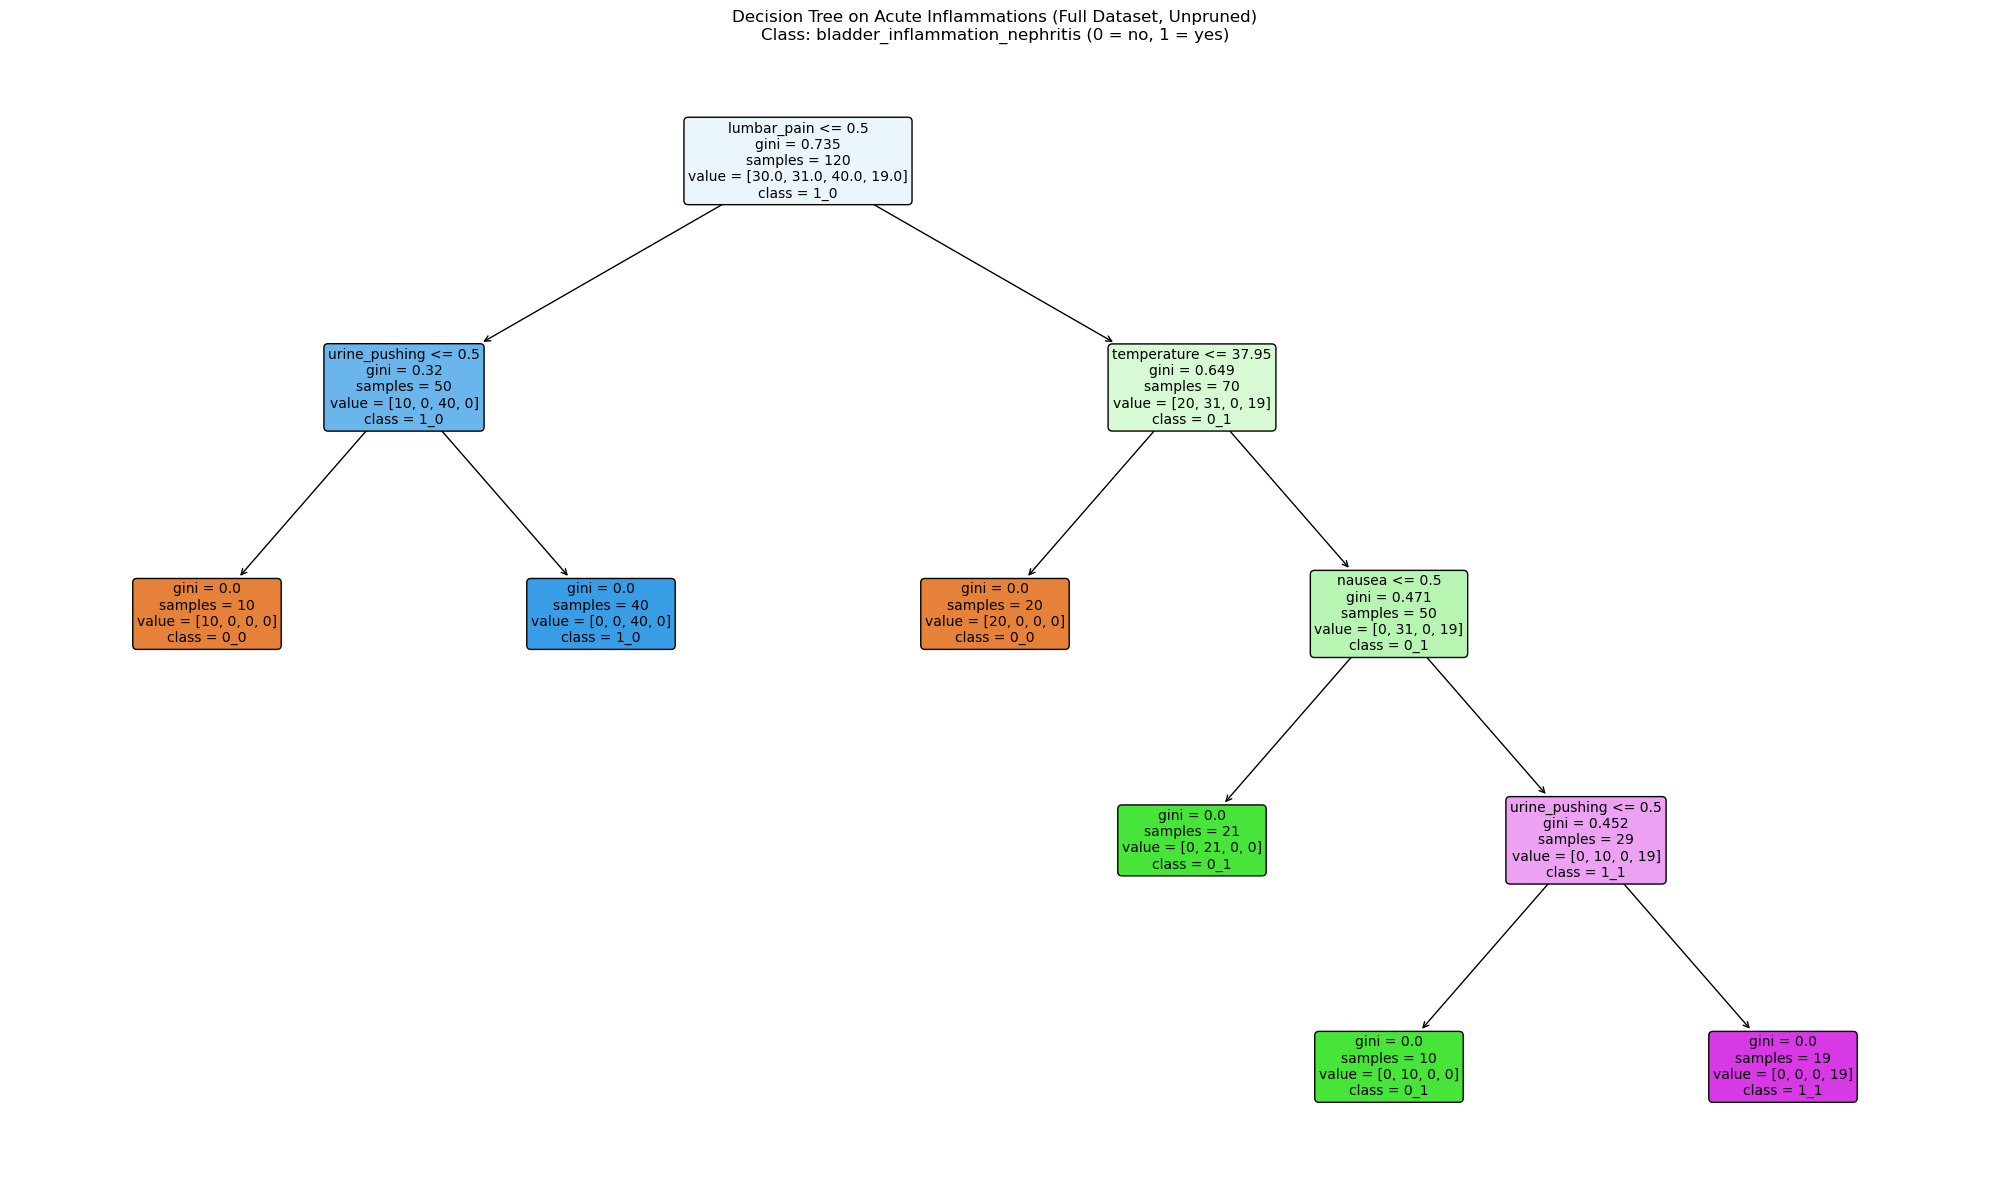

In [92]:
clf_full = DecisionTreeClassifier(random_state=42)
clf_full.fit(X, y)

class_names = clf_full.classes_.tolist()

print("Classes:", class_names)
print("Unpruned depth:", clf_full.get_depth())
print("Number of leaves:", clf_full.get_n_leaves())
print(f"Training accuracy: {clf_full.score(X, y):.4f}")

plt.figure(figsize=(20, 12))

plot_tree(
    clf_full,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False,
    fontsize=10
)

plt.title(
    "Decision Tree on Acute Inflammations (Full Dataset, Unpruned)\n"
    "Class: bladder_inflammation_nephritis (0 = no, 1 = yes)"
)

plt.tight_layout()
plt.show()

### (c) Convert the decision rules

In [94]:
def extract_if_then_rules(model, feature_names):
    tree_ = model.tree_
    rules = []

    diagnosis_names = {
        "0_0": "bladder_inflammation=no, nephritis=no",
        "0_1": "bladder_inflammation=no, nephritis=yes",
        "1_0": "bladder_inflammation=yes, nephritis=no",
        "1_1": "bladder_inflammation=yes, nephritis=yes"
    }

    def recurse(node, conditions):
        if tree_.feature[node] != -2:
            feature = feature_names[tree_.feature[node]]
            threshold = tree_.threshold[node]

            recurse(
                tree_.children_left[node],
                conditions + [f"{feature} <= {threshold:.3f}"]
            )

            recurse(
                tree_.children_right[node],
                conditions + [f"{feature} > {threshold:.3f}"]
            )

        else:
            class_index = np.argmax(tree_.value[node][0])
            class_label = model.classes_[class_index]
            prediction = diagnosis_names[class_label]
            n_samples = tree_.n_node_samples[node]

            condition_text = " AND ".join(conditions) if conditions else "TRUE"

            rules.append(
                f"IF {condition_text} "
                f"THEN {prediction} (n={n_samples})"
            )

    recurse(0, [])
    return rules


rules_full = extract_if_then_rules(clf_full, feature_names)

print(f"Extracted {len(rules_full)} rules:\n")

for i, rule in enumerate(rules_full, start=1):
    print(f"Rule {i}: {rule}\n")

Extracted 6 rules:

Rule 1: IF lumbar_pain <= 0.500 AND urine_pushing <= 0.500 THEN bladder_inflammation=no, nephritis=no (n=10)

Rule 2: IF lumbar_pain <= 0.500 AND urine_pushing > 0.500 THEN bladder_inflammation=yes, nephritis=no (n=40)

Rule 3: IF lumbar_pain > 0.500 AND temperature <= 37.950 THEN bladder_inflammation=no, nephritis=no (n=20)

Rule 4: IF lumbar_pain > 0.500 AND temperature > 37.950 AND nausea <= 0.500 THEN bladder_inflammation=no, nephritis=yes (n=21)

Rule 5: IF lumbar_pain > 0.500 AND temperature > 37.950 AND nausea > 0.500 AND urine_pushing <= 0.500 THEN bladder_inflammation=no, nephritis=yes (n=10)

Rule 6: IF lumbar_pain > 0.500 AND temperature > 37.950 AND nausea > 0.500 AND urine_pushing > 0.500 THEN bladder_inflammation=yes, nephritis=yes (n=19)



### (d) find a minimal decision tree and a set of decision rules with high interpretability

Cost-complexity pruning candidates:

 ccp_alpha  depth  leaves  train_accuracy  cv_accuracy    cv_se
  0.000000      4       6        1.000000     0.991667 0.008333
  0.098167      2       4        0.841667     0.858333 0.025000
  0.133333      2       3        0.758333     0.758333 0.033333
  0.182000      1       2        0.591667     0.666667 0.029463
  0.222917      0       1        0.333333     0.483333 0.061237

Best mean CV accuracy: 0.9917
One-SE threshold: 0.9833
Selected ccp_alpha: 0.000000
Selected CV accuracy: 0.9917
Unpruned leaves: 6
Selected tree leaves: 6
Selected tree depth: 4


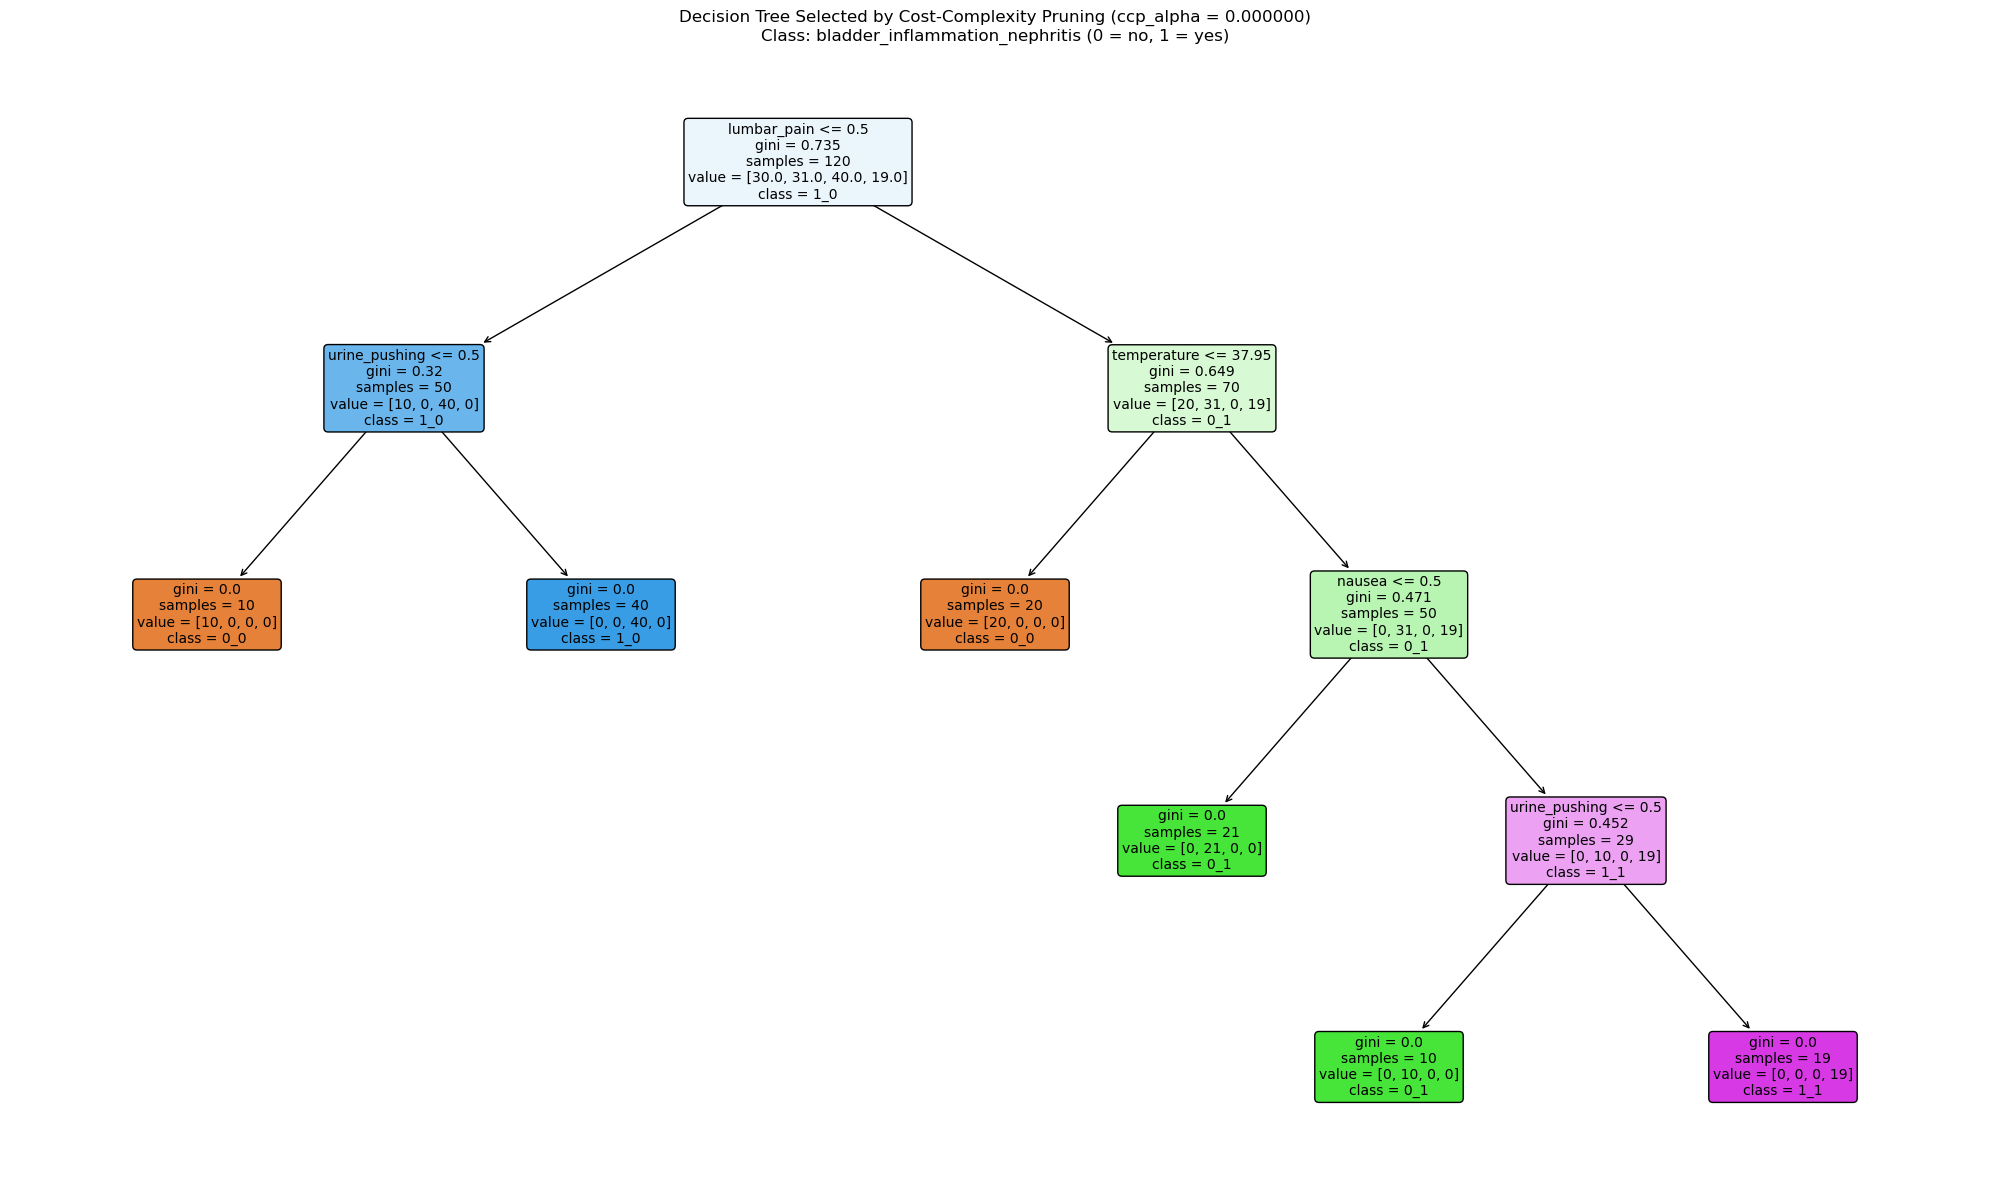


Selected tree has 6 rules:

Rule 1: IF lumbar_pain <= 0.500 AND urine_pushing <= 0.500 THEN bladder_inflammation=no, nephritis=no (n=10)

Rule 2: IF lumbar_pain <= 0.500 AND urine_pushing > 0.500 THEN bladder_inflammation=yes, nephritis=no (n=40)

Rule 3: IF lumbar_pain > 0.500 AND temperature <= 37.950 THEN bladder_inflammation=no, nephritis=no (n=20)

Rule 4: IF lumbar_pain > 0.500 AND temperature > 37.950 AND nausea <= 0.500 THEN bladder_inflammation=no, nephritis=yes (n=21)

Rule 5: IF lumbar_pain > 0.500 AND temperature > 37.950 AND nausea > 0.500 AND urine_pushing <= 0.500 THEN bladder_inflammation=no, nephritis=yes (n=10)

Rule 6: IF lumbar_pain > 0.500 AND temperature > 37.950 AND nausea > 0.500 AND urine_pushing > 0.500 THEN bladder_inflammation=yes, nephritis=yes (n=19)



In [98]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

path = clf_full.cost_complexity_pruning_path(X, y)
ccp_alphas = np.unique(np.maximum(path.ccp_alphas, 0))

records = []

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=float(alpha)
    )

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    model.fit(X, y)

    records.append({
        "ccp_alpha": float(alpha),
        "depth": model.get_depth(),
        "leaves": model.get_n_leaves(),
        "train_accuracy": model.score(X, y),
        "cv_accuracy": scores.mean(),
        "cv_se": scores.std(ddof=1) / np.sqrt(len(scores))
    })

cv_results = pd.DataFrame(records)

print("Cost-complexity pruning candidates:\n")
print(
    cv_results.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}"
    )
)

best_row = cv_results.loc[cv_results["cv_accuracy"].idxmax()]
threshold = best_row["cv_accuracy"] - best_row["cv_se"]

eligible = cv_results[
    cv_results["cv_accuracy"] >= threshold - 1e-12
]

selected_row = eligible.sort_values(
    by=["leaves", "cv_accuracy", "ccp_alpha"],
    ascending=[True, False, False]
).iloc[0]

best_alpha = float(selected_row["ccp_alpha"])

clf_pruned = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha
)
clf_pruned.fit(X, y)

print(f"\nBest mean CV accuracy: {best_row['cv_accuracy']:.4f}")
print(f"One-SE threshold: {threshold:.4f}")
print(f"Selected ccp_alpha: {best_alpha:.6f}")
print(f"Selected CV accuracy: {selected_row['cv_accuracy']:.4f}")
print(f"Unpruned leaves: {clf_full.get_n_leaves()}")
print(f"Selected tree leaves: {clf_pruned.get_n_leaves()}")
print(f"Selected tree depth: {clf_pruned.get_depth()}")

plt.figure(figsize=(20, 12))

plot_tree(
    clf_pruned,
    feature_names=feature_names,
    class_names=clf_pruned.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title(
    f"Decision Tree Selected by Cost-Complexity Pruning "
    f"(ccp_alpha = {best_alpha:.6f})\n"
    "Class: bladder_inflammation_nephritis (0 = no, 1 = yes)"
)

plt.tight_layout()
plt.show()

rules_pruned = extract_if_then_rules(
    clf_pruned,
    feature_names
)

print(f"\nSelected tree has {len(rules_pruned)} rules:\n")

for i, rule in enumerate(rules_pruned, start=1):
    print(f"Rule {i}: {rule}\n")

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [39]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/communities/communities.data"
response = requests.get(url)
response.raise_for_status()

df = pd.read_csv(io.BytesIO(response.content), header=None, na_values="?")

df = df.drop(columns=[0, 1, 2, 3, 4])

X_all = df.iloc[:, :-1]
y_all = df.iloc[:, -1]

X_train_raw = X_all.iloc[:1495].copy()
y_train = y_all.iloc[:1495].copy()
X_test_raw = X_all.iloc[1495:].copy()
y_test = y_all.iloc[1495:].copy()

print(f"Original dataset shape: {df.shape}")
print(f"Train set: {X_train_raw.shape[0]} samples, {X_train_raw.shape[1]} features")
print(f"Test set:  {X_test_raw.shape[0]} samples, {X_test_raw.shape[1]} features")

Original dataset shape: (1994, 123)
Train set: 1495 samples, 122 features
Test set:  499 samples, 122 features


### (b) Missing values

In [45]:
imputer = SimpleImputer(strategy="median")

imputer.fit(X_train_raw)

X_train = pd.DataFrame(imputer.transform(X_train_raw), columns=X_train_raw.columns)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns)

print(f"Remaining missing values in train: {X_train.isna().sum().sum()}")
print(f"Remaining missing values in test:  {X_test.isna().sum().sum()}")

print("\nFirst 3 rows of X_train after imputation:")
print(X_train.head(3))

Remaining missing values in train: 0
Remaining missing values in test:  0

First 3 rows of X_train after imputation:
    5     6     7     8     9     10    11    12    13    14   ...   117  \
0  0.19  0.33  0.02  0.90  0.12  0.17  0.34  0.47  0.29  0.32  ...  0.29   
1  0.00  0.16  0.12  0.74  0.45  0.07  0.26  0.59  0.35  0.27  ...  0.28   
2  0.00  0.42  0.49  0.56  0.17  0.04  0.39  0.47  0.28  0.32  ...  0.28   

    118   119   120   121   122   123  124   125   126  
0  0.12  0.26  0.20  0.06  0.04  0.90  0.5  0.32  0.14  
1  0.02  0.12  0.45  0.07  0.03  0.76  0.5  0.00  0.15  
2  0.01  0.21  0.02  0.07  0.03  0.76  0.5  0.00  0.15  

[3 rows x 122 columns]


### (c) Plot a correlation matrix

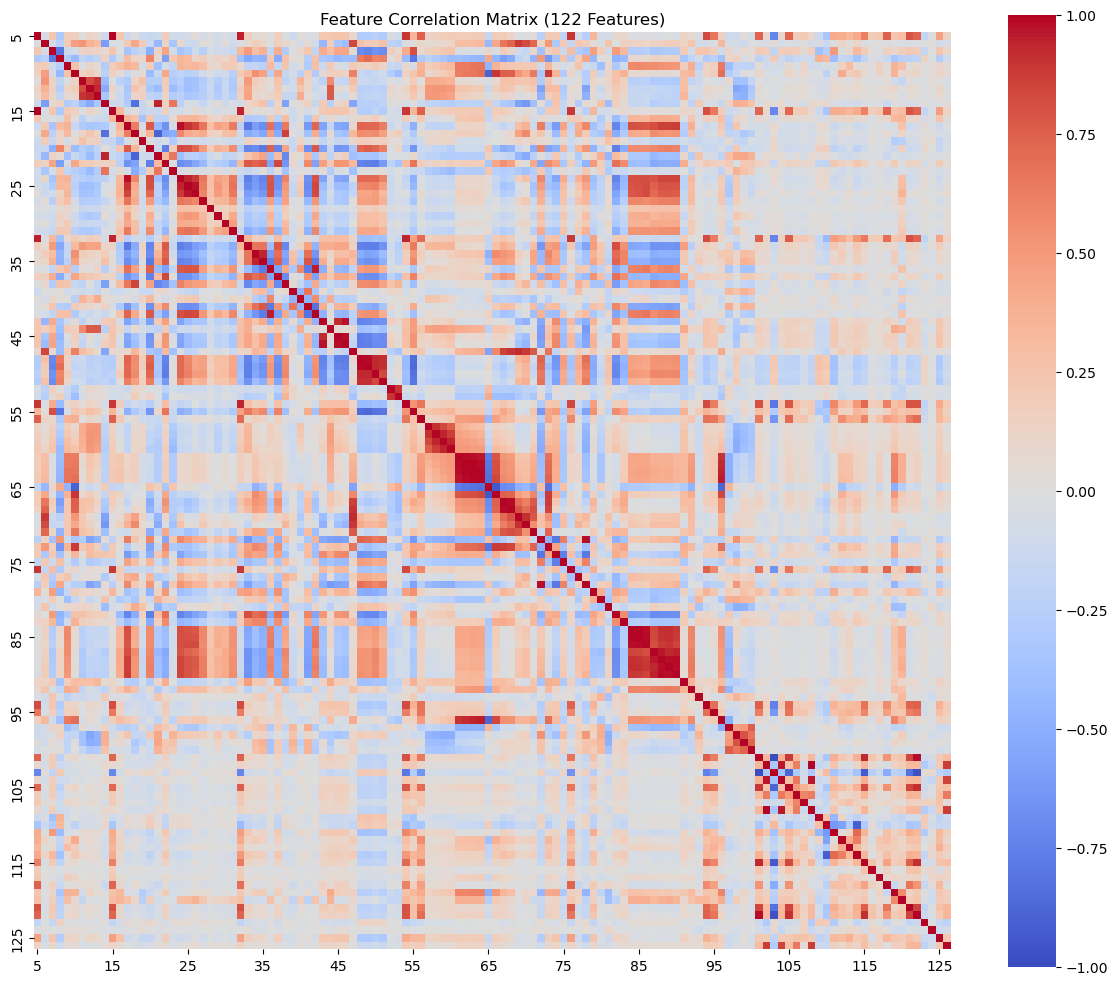

In [134]:
plt.figure(figsize=(12, 10))

corr_matrix = X_train.corr()

sns.heatmap(
    corr_matrix, 
    cmap="coolwarm",    
    vmin=-1, vmax=1,    
    xticklabels=10,
    yticklabels=10, 
    square=True
)

plt.title("Feature Correlation Matrix (122 Features)")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [51]:
means = X_train.mean()
stds = X_train.std()

cv_scores = stds / (means)

cv_scores_sorted = cv_scores.sort_values(ascending=False)

print("Top 20 features with the highest Coefficient of Variation (CV):")
print(cv_scores_sorted.head(20))

Top 20 features with the highest Coefficient of Variation (CV):
113    5.527059
95     4.292923
94     3.470952
54     3.058964
56     2.926635
125    2.552946
32     2.342443
101    2.248042
5      2.241105
15     2.038461
76     1.968467
122    1.645508
118    1.645408
10     1.612091
66     1.456618
105    1.451887
7      1.428885
120    1.397110
9      1.359100
112    1.353882
dtype: float64


### (e) Scatter plots and box plots for highest CV features

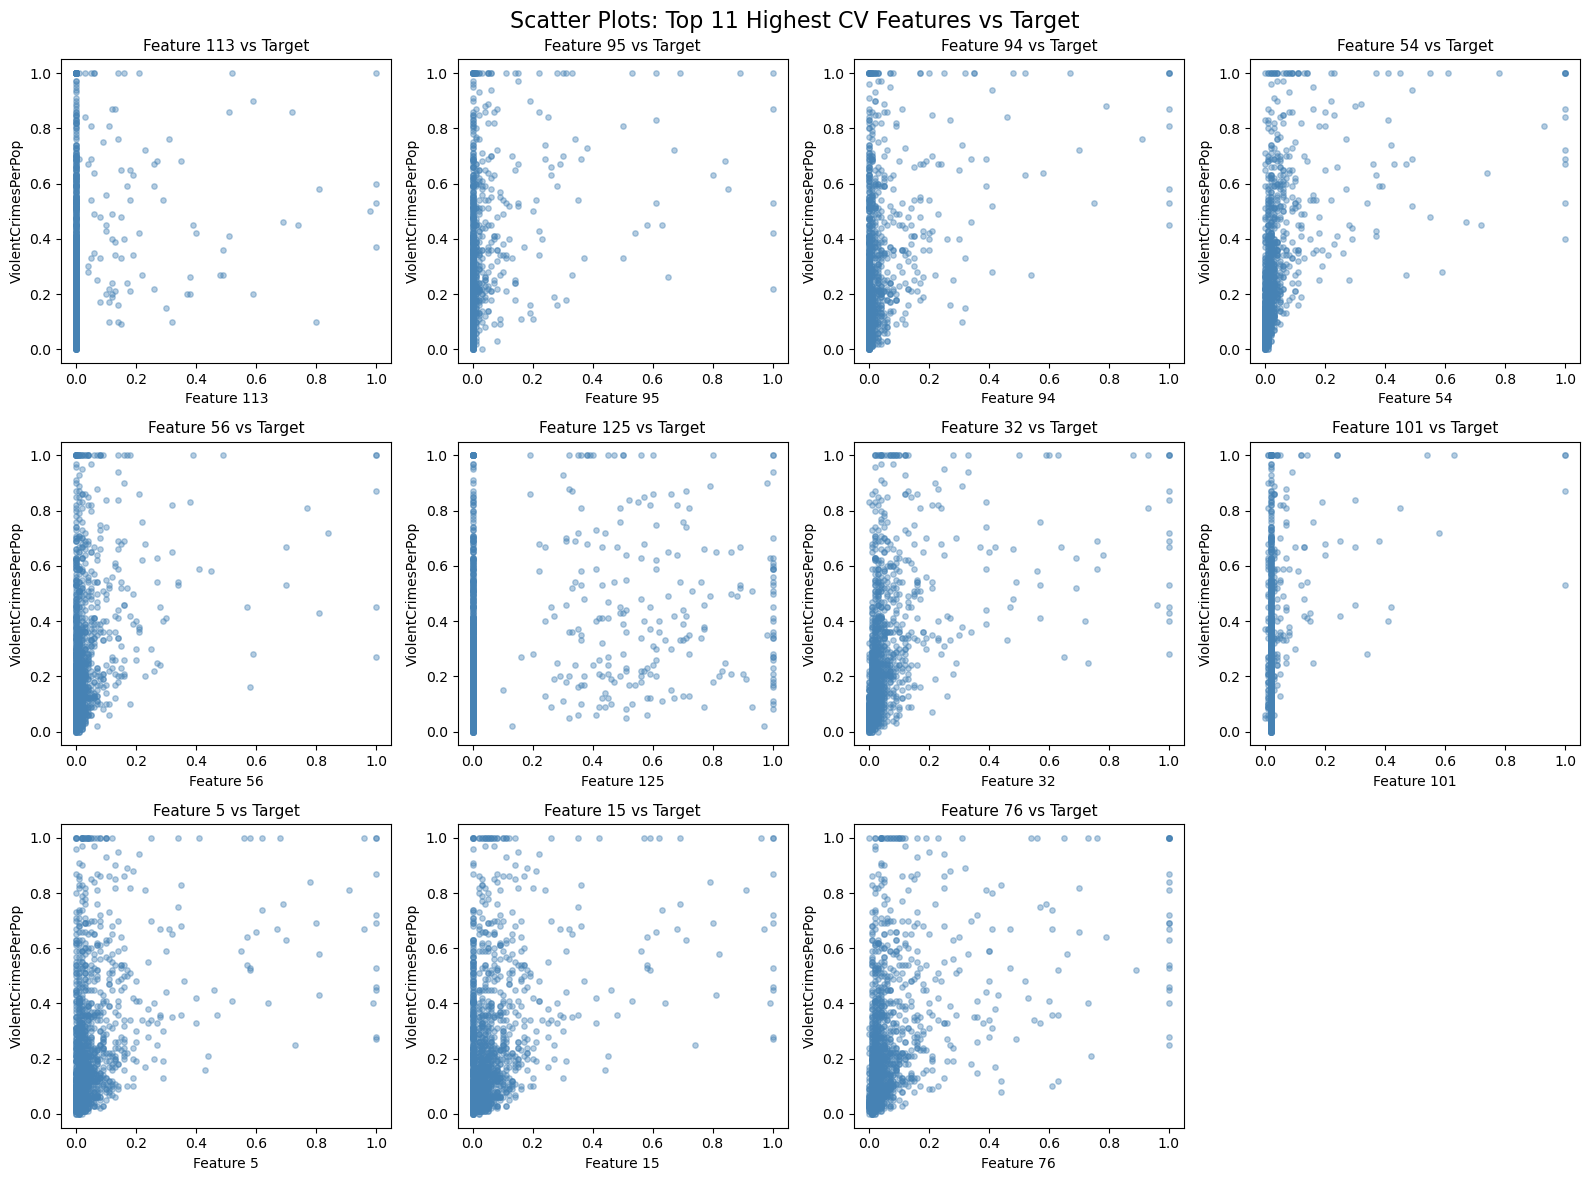

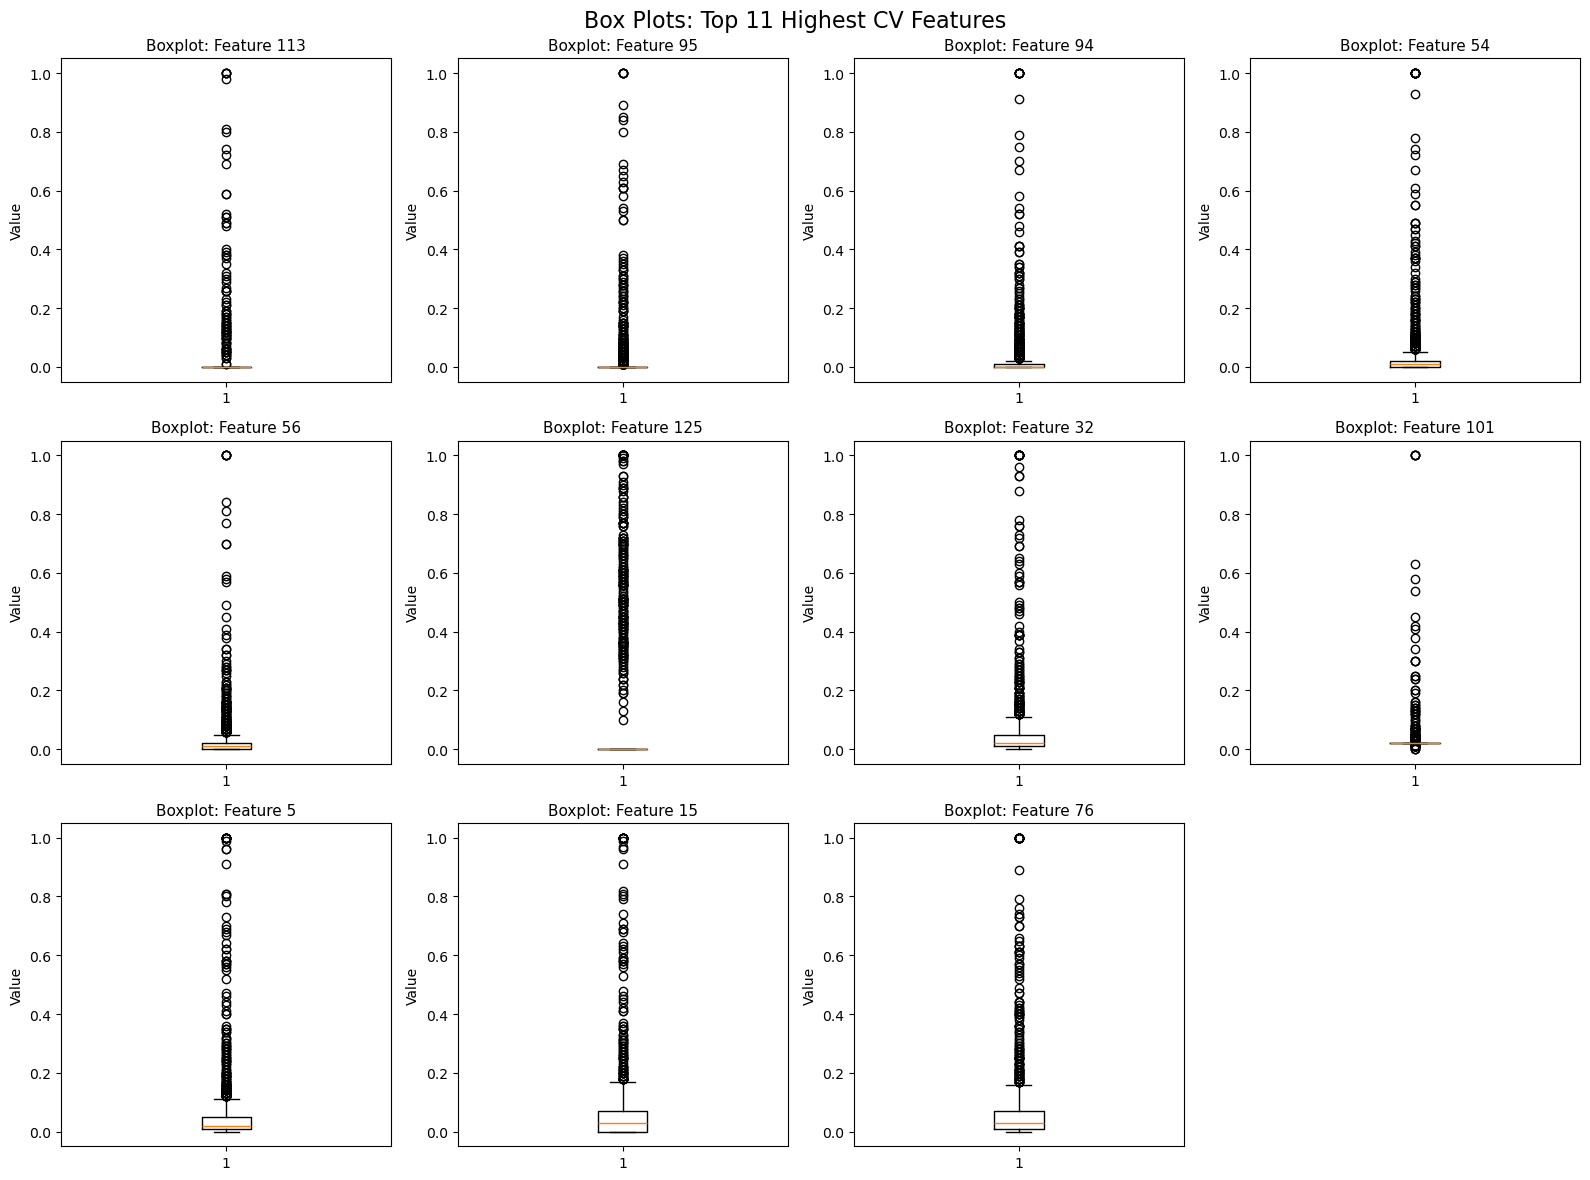

In [53]:
top_11_features = cv_scores.sort_values(ascending=False).head(11).index.tolist()

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, feat in enumerate(top_11_features):
    axes[i].scatter(X_train[feat], y_train, alpha=0.4, s=15, color='steelblue')
    axes[i].set_xlabel(f"Feature {feat}", fontsize=10)
    axes[i].set_ylabel("ViolentCrimesPerPop", fontsize=10)
    axes[i].set_title(f"Feature {feat} vs Target", fontsize=11)

axes[-1].axis('off') 
plt.suptitle("Scatter Plots: Top 11 Highest CV Features vs Target", fontsize=16)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, feat in enumerate(top_11_features):
    axes[i].boxplot(X_train[feat].dropna())
    axes[i].set_title(f"Boxplot: Feature {feat}", fontsize=11)
    axes[i].set_ylabel("Value", fontsize=10)

axes[-1].axis('off')
plt.suptitle("Box Plots: Top 11 Highest CV Features", fontsize=16)
plt.tight_layout()
plt.show()

No.

Univariate Limitation: Scatter plots only show the marginal (univariate) relationship between a single feature and the target. If a scatter plot looks like a mess (no clear linear trend), it doesn't mean the feature is unimportant in a multivariate regression; conversely, a visible trend doesn't guarantee significance.

Multicollinearity: The Communities and Crime dataset has severe multicollinearity (as seen in your 2(c) heatmap). A feature showing a strong correlation in a scatter plot might just be "free-riding" on another highly correlated, truly predictive feature.

Interaction Effects: Scatter plots cannot reveal interactions between features. Some features may only be predictive when combined with others.

Outliers: As seen in the box plots, features with high CV often contain many extreme outliers. These outliers can severely distort the visual trend in scatter plots.

### (f) Fit a linear model

In [102]:
ols_model = LinearRegression()

ols_model.fit(X_train, y_train)

y_pred_ols = ols_model.predict(X_test)

mse_ols = mean_squared_error(y_test, y_pred_ols)
r2_ols = r2_score(y_test, y_pred_ols)

print(f"OLS Test Mean Squared Error (MSE): {mse_ols:.6f}")
print(f"OLS Test R-squared (R2): {r2_ols:.6f}")

OLS Test Mean Squared Error (MSE): 0.017966
OLS Test R-squared (R2): 0.622204


### (g) Fit a ridge regression model

In [106]:
ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("ridge", Ridge())
])

param_grid_ridge = {
    "ridge__alpha": np.logspace(-3, 5, 100)
}

ridge_model = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid_ridge,
    cv=5,
    scoring="neg_mean_squared_error"
)

ridge_model.fit(X_train_raw, y_train)

y_pred_ridge = ridge_model.predict(X_test_raw)

mse_ridge = mean_squared_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print(
    "Best lambda (alpha) chosen by CV: "
    f"{ridge_model.best_params_['ridge__alpha']:.6f}"
)
print(f"Best CV MSE: {-ridge_model.best_score_:.6f}")
print(f"Ridge Test Mean Squared Error (MSE): {mse_ridge:.6f}")
print(f"Ridge Test R-squared (R2): {r2_ridge:.6f}")

Best lambda (alpha) chosen by CV: 2.477076
Best CV MSE: 0.019050
Ridge Test Mean Squared Error (MSE): 0.017508
Ridge Test R-squared (R2): 0.631847


### (h) Fit a LASSO model

In [130]:
lasso_alphas = np.logspace(-5, -1, 100)

lasso_results = []
lasso_models = {}

for label, standardize in [
    ("Raw Features", False),
    ("Standardized Features", True)
]:
    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if standardize:
        steps.append(("scaler", StandardScaler()))

    steps.append(("lasso", Lasso(max_iter=100000)))

    pipeline = Pipeline(steps)

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"lasso__alpha": lasso_alphas},
        cv=5,
        scoring="neg_mean_squared_error"
    )

    search.fit(X_train_raw, y_train)

    y_pred = search.predict(X_test_raw)
    test_mse = mean_squared_error(y_test, y_pred)
    test_r2 = r2_score(y_test, y_pred)

    coefficients = search.best_estimator_.named_steps["lasso"].coef_

    selected_features = X_train_raw.columns[
        coefficients != 0
    ].tolist()

    lasso_models[label] = search

    print(f"LASSO ({label}) ")
    print(f"Best alpha: {search.best_params_['lasso__alpha']:.8f}")
    print(f"Best CV MSE: {-search.best_score_:.6f}")
    print(f"Test MSE: {test_mse:.6f}")
    print(f"Test R2: {test_r2:.6f}")
    print(f"Number of selected features: {len(selected_features)}")
    print(f"Selected features: {selected_features}\n")

    lasso_results.append({
        "Model": label,
        "Test MSE": test_mse,
        "Selected features": len(selected_features)
    })

lasso_comparison = pd.DataFrame(lasso_results)

print("Comparison:")
print(lasso_comparison.to_string(index=False))

LASSO (Raw Features) 
Best alpha: 0.00012328
Best CV MSE: 0.018978
Test MSE: 0.017620
Test R2: 0.629486
Number of selected features: 74
Selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 57, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 104, 107, 109, 111, 112, 113, 116, 117, 118, 119, 120, 121, 123, 124]

LASSO (Standardized Features) 
Best alpha: 0.00079248
Best CV MSE: 0.019015
Test MSE: 0.017674
Test R2: 0.628340
Number of selected features: 72
Selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 58, 60, 64, 66, 68, 69, 72, 73, 74, 76, 77, 79, 80, 81, 82, 83, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124]

Comparison:
                Model  Test MSE  Selected features
    

Without additional standardization, cross-validation selects α = 0.00012328. The model retains 74 predictors and achieves a test MSE of 0.017620. After standardization, the selected α is 0.00079248, with 72 predictors retained and a test MSE of 0.017674. Thus, standardization produces a slightly sparser model but does not improve test MSE in this experiment. The difference in test error is small, indicating similar predictive performance.

### (i) Fit a PCR model

In [128]:
pcr_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="median")),
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('lr', LinearRegression())
])

param_grid = {'pca__n_components': range(1, X_train.shape[1] + 1)}

pcr_grid = GridSearchCV(pcr_pipeline, param_grid, cv=5, scoring='neg_mean_squared_error')
pcr_grid.fit(X_train_raw, y_train)

best_m = pcr_grid.best_params_['pca__n_components']
y_pred_pcr = pcr_grid.predict(X_test_raw)
mse_pcr = mean_squared_error(y_test, y_pred_pcr)
r2_pcr = r2_score(y_test, y_pred_pcr)

print(f"PCR Model")
print(f"Best number of components (M): {best_m}")
print(f"PCR Test Mean Squared Error (MSE): {mse_pcr:.6f}")
print(f"PCR Test R-squared (R2): {r2_pcr:.6f}")

PCR Model
Best number of components (M): 95
PCR Test Mean Squared Error (MSE): 0.018298
PCR Test R-squared (R2): 0.615235


### (j) Fit a boosting tree

In [121]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [131]:
import xgboost as xgb
xgb_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", xgb_model)
])

param_grid_xgb = {
    "xgb__alpha": [0, 0.01, 0.1, 1, 10]
}

xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid_xgb,
    cv=5,
    scoring="neg_mean_squared_error"
)

xgb_grid.fit(X_train_raw, y_train)

best_alpha_xgb = xgb_grid.best_params_["xgb__alpha"]
best_xgb = xgb_grid.best_estimator_

y_pred_xgb = best_xgb.predict(X_test_raw)

mse_xgb = mean_squared_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost Model ")
print(f"Best alpha (L1 penalty): {best_alpha_xgb}")
print(f"XGBoost Test Mean Squared Error (MSE): {mse_xgb:.6f}")
print(f"XGBoost Test R-squared (R2): {r2_xgb:.6f}")

XGBoost Model 
Best alpha (L1 penalty): 1
XGBoost Test Mean Squared Error (MSE): 0.017927
XGBoost Test R-squared (R2): 0.623026
